# Anàlisi exploratòria i resultats: Mode Estàndard i Mode Difícil (3 bateries)

Comparativa de les dades horàries del Campus Nord (UPC) i validació dels agents finals `estandard_robust` (1 bateria: 2.000 kWh, ±500 kW) i `dificil_marges` (3 bateries: 6.000 kWh, ±1.500 kW, solar ×12).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data import load_hourly
from src.evaluate import valid_split, load_agent, run, oracle

PAPER = '#F6F4EF'
SURFACE = '#FFFFFF'
INK = '#1C1F22'
MUTED = '#6B6760'
RULE = '#DAD6CE'
ACCENT = '#0F5C4D'
REF = '#A9A49B'
SOLAR = '#E69F00'
CO2_COL = '#87603A'
PRICE_COL = '#7A5195'
WARN = '#D55E00'

plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': SURFACE,
    'axes.edgecolor': RULE,
    'axes.labelcolor': MUTED,
    'xtick.color': MUTED,
    'ytick.color': MUTED,
    'text.color': INK,
    'font.sans-serif': ['IBM Plex Sans', 'DejaVu Sans', 'sans-serif'],
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.grid.axis': 'y',
    'grid.color': RULE,
    'grid.alpha': 0.6,
    'savefig.dpi': 220,
})

FIG_DIR = ROOT / 'docs' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_hourly()
df['net_std_kw'] = df['load_kw'] - df['pv_kw']
df['net_hard_kw'] = df['load_kw'] - 12.0 * df['pv_kw']
df['co2_g_kwh'] = df['co2_kg_per_kwh'] * 1000.0
df['price_eur_mwh'] = df['precio_eur_per_kwh'] * 1000.0
print(f'Hores: {len(df)} | Consum mitja: {df.load_kw.mean():.0f} kW | Solar x1 max: {df.pv_kw.max():.0f} kW | Solar x12 max: {12*df.pv_kw.max():.0f} kW')

Hores: 5993 | Consum mitja: 1123 kW | Solar x1 max: 144 kW | Solar x12 max: 1729 kW


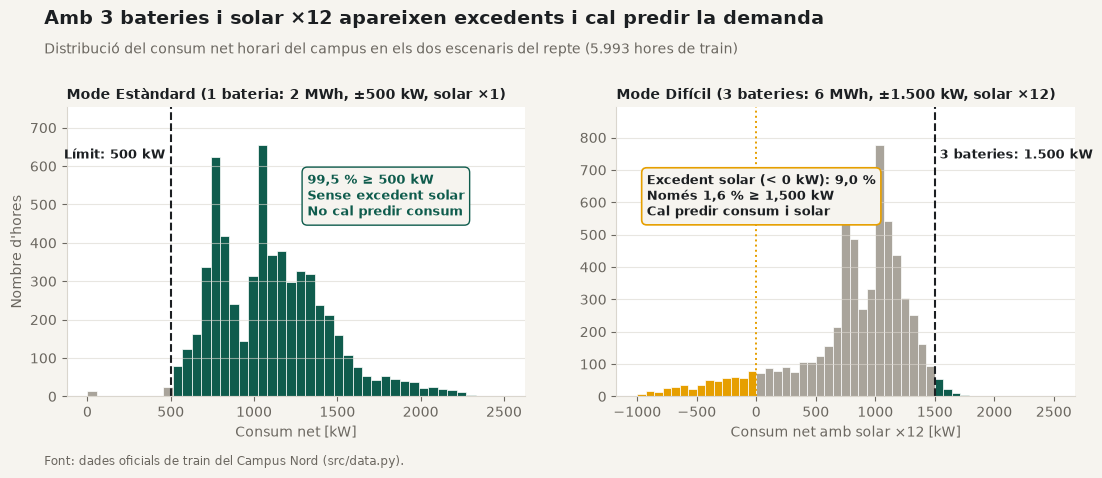

In [2]:
# Grafic 1 (Diapositiva 2): Per que el Mode Dificil (3 bateries, solar x12) canvia el problema
pct_std = (df['net_std_kw'] >= 500).mean() * 100
pct_hard_above = (df['net_hard_kw'] >= 1500).mean() * 100
pct_hard_surplus = (df['net_hard_kw'] < 0).mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.9))
fig.subplots_adjust(left=0.07, right=0.97, top=0.75, bottom=0.16, wspace=0.20)

# Panell esquerre: Mode Estandard (1 bateria)
bins_s = np.linspace(0, 2500, 45)
cs, es, ps = axes[0].hist(df['net_std_kw'], bins=bins_s, edgecolor=SURFACE, linewidth=0.5)
for left, patch in zip(es[:-1], ps):
    patch.set_facecolor(REF if left < 500 else ACCENT)
axes[0].set_ylim(0, cs.max() * 1.15)
axes[0].axvline(500, color=INK, linestyle='--', linewidth=1.5)
axes[0].text(465, cs.max() * 0.96, 'Límit: 500 kW', ha='right', va='center', fontsize=9.5, fontweight='bold')
axes[0].text(
    1320, cs.max() * 0.72,
    f'{pct_std:.1f} % ≥ 500 kW\nSense excedent solar\nNo cal predir consum'.replace('.', ','),
    color=ACCENT, fontsize=9.5, fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.4', facecolor=PAPER, edgecolor=ACCENT, linewidth=1)
)
axes[0].set_title('Mode Estàndard (1 bateria: 2 MWh, ±500 kW, solar ×1)', fontsize=10, fontweight='bold', loc='left')
axes[0].set_xlabel('Consum net [kW]')
axes[0].set_ylabel("Nombre d'hores")

# Panell dret: Mode Dificil (3 bateries, solar x12)
bins_h = np.linspace(-1000, 2500, 50)
ch, eh, ph = axes[1].hist(df['net_hard_kw'], bins=bins_h, edgecolor=SURFACE, linewidth=0.5)
for left, patch in zip(eh[:-1], ph):
    if left < 0:
        patch.set_facecolor(SOLAR)
    elif left < 1500:
        patch.set_facecolor(REF)
    else:
        patch.set_facecolor(ACCENT)
axes[1].set_ylim(0, ch.max() * 1.15)
axes[1].axvline(0, color=SOLAR, linestyle=':', linewidth=1.4)
axes[1].axvline(1500, color=INK, linestyle='--', linewidth=1.5)
axes[1].text(1540, ch.max() * 0.96, '3 bateries: 1.500 kW', ha='left', va='center', fontsize=9.5, fontweight='bold')
axes[1].text(
    -920, ch.max() * 0.72,
    f'Excedent solar (< 0 kW): {pct_hard_surplus:.1f} %\nNomés {pct_hard_above:.1f} % ≥ 1.500 kW\nCal predir consum i solar'.replace('.', ','),
    color=INK, fontsize=9.2, fontweight='bold',
    bbox=dict(boxstyle='round,pad=0.4', facecolor=PAPER, edgecolor=SOLAR, linewidth=1.2)
)
axes[1].set_title('Mode Difícil (3 bateries: 6 MWh, ±1.500 kW, solar ×12)', fontsize=10, fontweight='bold', loc='left')
axes[1].set_xlabel('Consum net amb solar ×12 [kW]')

fig.text(0.05, 0.92, 'Amb 3 bateries i solar ×12 apareixen excedents i cal predir la demanda', fontsize=13.5, fontweight='bold')
fig.text(0.05, 0.86, 'Distribució del consum net horari del campus en els dos escenaris del repte (5.993 hores de train)', fontsize=10, color=MUTED)
fig.text(0.05, 0.02, 'Font: dades oficials de train del Campus Nord (src/data.py).', fontsize=8.5, color=MUTED)

fig.savefig(FIG_DIR / '01_consum_net_modes.png', bbox_inches='tight', pad_inches=0.25)
plt.show()

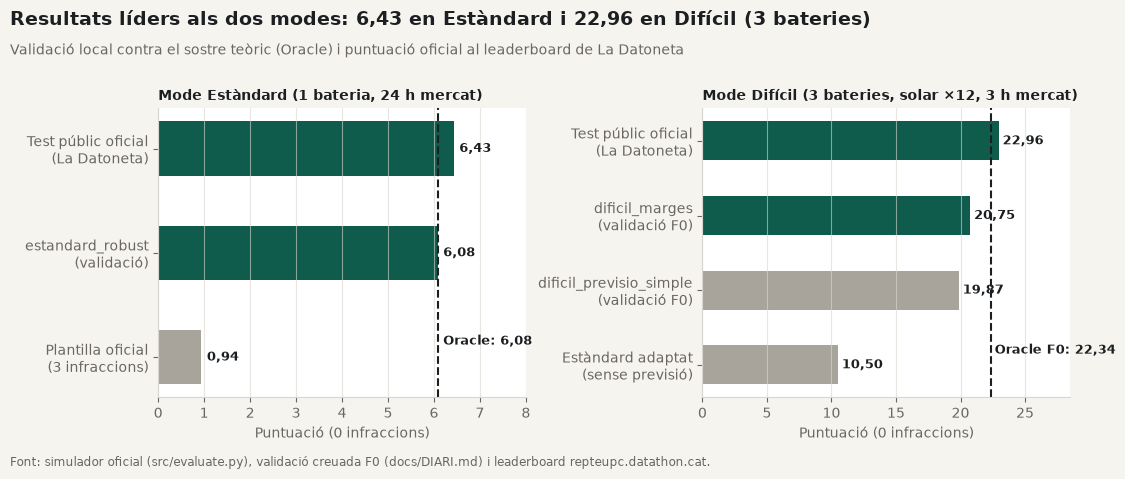

In [3]:
# Grafic 2 (Diapositiva 5): Resultats finals en Mode Estandard i Mode Dificil
val_df = valid_split(df)
res_base = run(load_agent(str(ROOT / 'starter_kit')), val_df)
res_std = run(load_agent(str(ROOT / 'agents' / 'estandard_robust')), val_df)
res_ora = oracle(val_df)

fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.9))
fig.subplots_adjust(left=0.17, right=0.97, top=0.75, bottom=0.16, wspace=0.48)

# Panell esquerre: Mode Estandard
lbl_s = ['Plantilla oficial\n(3 infraccions)', 'estandard_robust\n(validació)', 'Test públic oficial\n(La Datoneta)']
val_s = [res_base['score'], res_std['score'], 6.43]
col_s = [REF, ACCENT, ACCENT]
axes[0].grid(axis='x', color=RULE, alpha=0.6)
axes[0].grid(axis='y', visible=False)
bs = axes[0].barh(lbl_s, val_s, color=col_s, height=0.52)
axes[0].axvline(res_ora['score'], color=INK, linestyle='--', linewidth=1.5)
axes[0].text(res_ora['score'] + 0.12, 0.12, f"Oracle: {res_ora['score']:.2f}".replace('.', ','), fontsize=9, fontweight='bold')
for bar, sc in zip(bs, val_s):
    axes[0].text(sc + 0.12, bar.get_y() + bar.get_height()/2, f'{sc:.2f}'.replace('.', ','), va='center', fontsize=9.5, fontweight='bold')
axes[0].set_xlim(0, 8.0)
axes[0].set_title('Mode Estàndard (1 bateria, 24 h mercat)', fontsize=10, fontweight='bold', loc='left')
axes[0].set_xlabel('Puntuació (0 infraccions)')

# Panell dret: Mode Dificil (3 bateries)
lbl_h = ['Estàndard adaptat\n(sense previsió)', 'dificil_previsio_simple\n(validació F0)', 'dificil_marges\n(validació F0)', 'Test públic oficial\n(La Datoneta)']
val_h = [10.50, 19.87, 20.75, 22.96]
col_h = [REF, REF, ACCENT, ACCENT]
axes[1].grid(axis='x', color=RULE, alpha=0.6)
axes[1].grid(axis='y', visible=False)
bh = axes[1].barh(lbl_h, val_h, color=col_h, height=0.52)
axes[1].axvline(22.34, color=INK, linestyle='--', linewidth=1.5)
axes[1].text(22.65, 0.15, 'Oracle F0: 22,34', fontsize=9, fontweight='bold')
for bar, sc in zip(bh, val_h):
    axes[1].text(sc + 0.30, bar.get_y() + bar.get_height()/2, f'{sc:.2f}'.replace('.', ','), va='center', fontsize=9.5, fontweight='bold')
axes[1].set_xlim(0, 28.5)
axes[1].set_title('Mode Difícil (3 bateries, solar ×12, 3 h mercat)', fontsize=10, fontweight='bold', loc='left')
axes[1].set_xlabel('Puntuació (0 infraccions)')

fig.text(0.04, 0.92, 'Resultats líders als dos modes: 6,43 en Estàndard i 22,96 en Difícil (3 bateries)', fontsize=13.5, fontweight='bold')
fig.text(0.04, 0.86, 'Validació local contra el sostre teòric (Oracle) i puntuació oficial al leaderboard de La Datoneta', fontsize=10, color=MUTED)
fig.text(0.04, 0.02, 'Font: simulador oficial (src/evaluate.py), validació creuada F0 (docs/DIARI.md) i leaderboard repteupc.datathon.cat.', fontsize=8.5, color=MUTED)

fig.savefig(FIG_DIR / '02_comparativa_ambdos_modes.png', bbox_inches='tight', pad_inches=0.25)
plt.show()

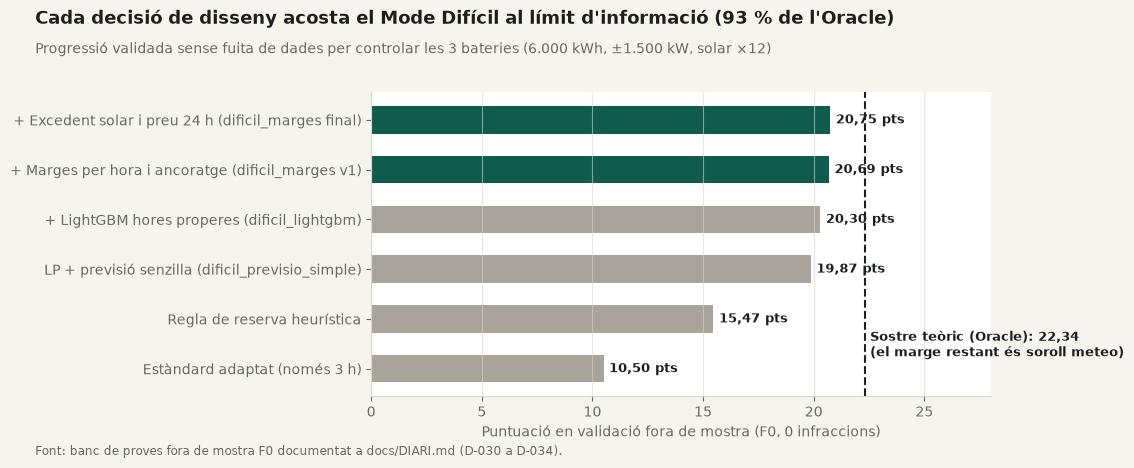

In [4]:
# Grafic 3: Evolucio de les millores en el Mode Dificil (3 bateries)
etapes = [
    'Estàndard adaptat (només 3 h)',
    'Regla de reserva heurística',
    'LP + previsió senzilla (dificil_previsio_simple)',
    '+ LightGBM hores properes (dificil_lightgbm)',
    '+ Marges per hora i ancoratge (dificil_marges v1)',
    '+ Excedent solar i preu 24 h (dificil_marges final)'
]
punts = [10.50, 15.47, 19.87, 20.30, 20.69, 20.75]
cols = [REF, REF, REF, REF, ACCENT, ACCENT]

fig, ax = plt.subplots(figsize=(10.5, 4.9))
fig.subplots_adjust(left=0.36, right=0.95, top=0.77, bottom=0.15)
ax.grid(axis='x', color=RULE, alpha=0.6)
ax.grid(axis='y', visible=False)

bars = ax.barh(etapes, punts, color=cols, height=0.55)
ax.axvline(22.34, color=INK, linestyle='--', linewidth=1.5)
ax.text(22.55, 0.25, 'Sostre teòric (Oracle): 22,34\n(el marge restant és soroll meteo)', fontsize=9, fontweight='bold')

for bar, sc in zip(bars, punts):
    ax.text(sc + 0.25, bar.get_y() + bar.get_height()/2, f'{sc:.2f} pts'.replace('.', ','), va='center', fontsize=9.5, fontweight='bold')

ax.set_xlim(0, 28.0)
ax.set_xlabel('Puntuació en validació fora de mostra (F0, 0 infraccions)')
fig.text(0.04, 0.91, 'Cada decisió de disseny acosta el Mode Difícil al límit d\'informació (93 % de l\'Oracle)', fontsize=13, fontweight='bold')
fig.text(0.04, 0.85, 'Progressió validada sense fuita de dades per controlar les 3 bateries (6.000 kWh, ±1.500 kW, solar ×12)', fontsize=10, color=MUTED)
fig.text(0.04, 0.03, 'Font: banc de proves fora de mostra F0 documentat a docs/DIARI.md (D-030 a D-034).', fontsize=8.5, color=MUTED)

fig.savefig(FIG_DIR / '03_evolucio_dificil_marges.png', bbox_inches='tight', pad_inches=0.25)
plt.show()

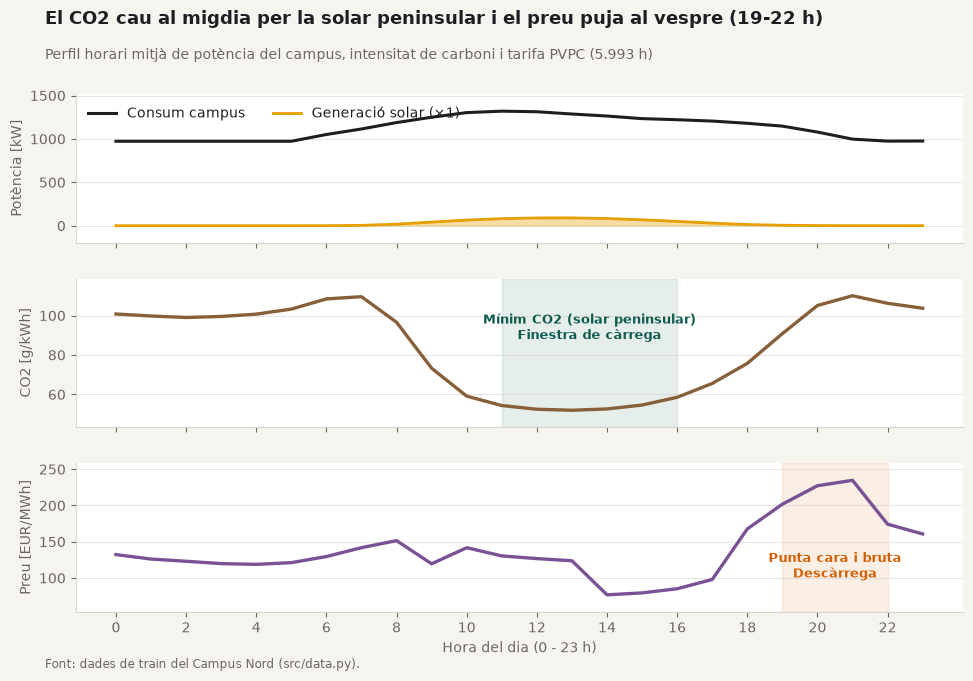

In [5]:
# Grafic 4: Patro horari mitja (consum, solar, CO2 i preu PVPC)
hourly_avg = df.groupby(df.index.hour).mean(numeric_only=True)

fig, axes = plt.subplots(3, 1, figsize=(10.2, 7.0), sharex=True)
fig.subplots_adjust(left=0.09, right=0.96, top=0.84, bottom=0.10, hspace=0.24)

axes[0].plot(hourly_avg.index, hourly_avg['load_kw'], color=INK, linewidth=2.2, label='Consum campus')
axes[0].fill_between(hourly_avg.index, 0, hourly_avg['pv_kw'], color=SOLAR, alpha=0.35)
axes[0].plot(hourly_avg.index, hourly_avg['pv_kw'], color=SOLAR, linewidth=2.0, label='Generació solar (×1)')
axes[0].set_ylabel('Potència [kW]')
axes[0].margins(y=0.15)
axes[0].legend(frameon=False, loc='upper left', ncol=2)

co2_min, co2_max = hourly_avg['co2_g_kwh'].min(), hourly_avg['co2_g_kwh'].max()
axes[1].plot(hourly_avg.index, hourly_avg['co2_g_kwh'], color=CO2_COL, linewidth=2.4)
axes[1].axvspan(11, 16, color=ACCENT, alpha=0.10)
axes[1].text(
    13.5, co2_min + (co2_max - co2_min) * 0.72,
    'Mínim CO2 (solar peninsular)\nFinestra de càrrega',
    ha='center', va='center', color=ACCENT, fontsize=9, fontweight='bold'
)
axes[1].set_ylabel('CO2 [g/kWh]')
axes[1].margins(y=0.15)

pr_min, pr_max = hourly_avg['price_eur_mwh'].min(), hourly_avg['price_eur_mwh'].max()
axes[2].plot(hourly_avg.index, hourly_avg['price_eur_mwh'], color=PRICE_COL, linewidth=2.4)
axes[2].axvspan(19, 22, color=WARN, alpha=0.10)
axes[2].text(
    20.5, pr_min + (pr_max - pr_min) * 0.25,
    'Punta cara i bruta\nDescàrrega',
    ha='center', va='center', color=WARN, fontsize=9, fontweight='bold'
)
axes[2].set_ylabel('Preu [EUR/MWh]')
axes[2].set_xlabel('Hora del dia (0 - 23 h)')
axes[2].set_xticks(range(0, 24, 2))
axes[2].margins(y=0.15)

fig.text(0.06, 0.94, 'El CO2 cau al migdia per la solar peninsular i el preu puja al vespre (19-22 h)', fontsize=13, fontweight='bold')
fig.text(0.06, 0.89, 'Perfil horari mitjà de potència del campus, intensitat de carboni i tarifa PVPC (5.993 h)', fontsize=10, color=MUTED)
fig.text(0.06, 0.02, 'Font: dades de train del Campus Nord (src/data.py).', fontsize=8.5, color=MUTED)

fig.savefig(FIG_DIR / '04_patro_horari_solar_co2_preu.png', bbox_inches='tight', pad_inches=0.25)
plt.show()

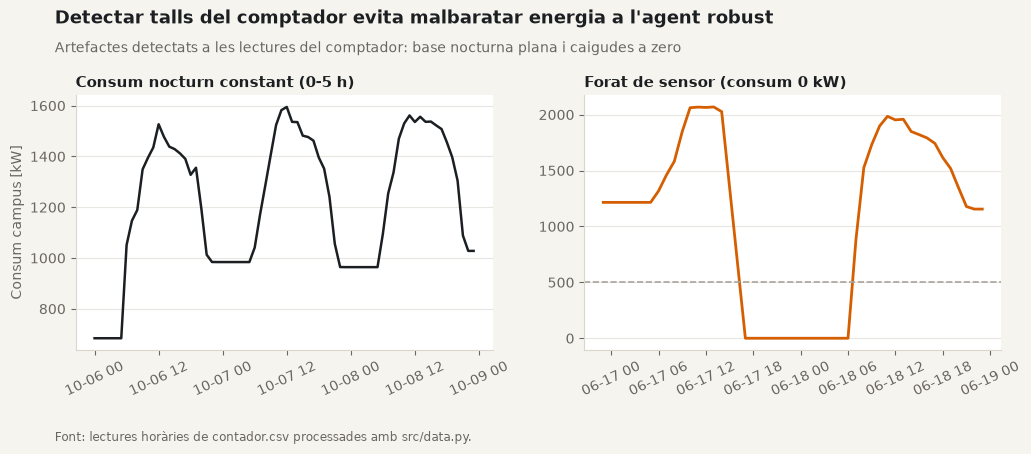

In [6]:
# Grafic 5: Qualitat de les dades (consum nocturn pla i talls del comptador)
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.8))
fig.subplots_adjust(left=0.08, right=0.97, top=0.75, bottom=0.22, wspace=0.22)

sample_days = df.loc['2025-10-06':'2025-10-08']
if len(sample_days) == 0:
    sample_days = df.iloc[24:96]
axes[0].plot(sample_days.index, sample_days['load_kw'], color=INK, linewidth=1.8)
axes[0].set_title('Consum nocturn constant (0-5 h)', fontsize=10.5, fontweight='bold', loc='left')
axes[0].set_ylabel('Consum campus [kW]')
axes[0].tick_params(axis='x', rotation=25)

zero_idx = df.index[df['load_kw'] == 0]
if len(zero_idx) > 0:
    t0 = zero_idx[0] - pd.Timedelta(hours=18)
    t1 = zero_idx[0] + pd.Timedelta(hours=30)
    outage = df.loc[t0:t1]
else:
    outage = df.loc['2026-06-16':'2026-06-18']
axes[1].plot(outage.index, outage['load_kw'], color=WARN, linewidth=2.0)
axes[1].axhline(500, color=REF, linestyle='--', linewidth=1.2)
axes[1].set_title('Forat de sensor (consum 0 kW)', fontsize=10.5, fontweight='bold', loc='left')
axes[1].tick_params(axis='x', rotation=25)

fig.text(0.06, 0.90, "Detectar talls del comptador evita malbaratar energia a l'agent robust", fontsize=13, fontweight='bold')
fig.text(0.06, 0.84, 'Artefactes detectats a les lectures del comptador: base nocturna plana i caigudes a zero', fontsize=10, color=MUTED)
fig.text(0.06, 0.03, 'Font: lectures horàries de contador.csv processades amb src/data.py.', fontsize=8.5, color=MUTED)

fig.savefig(FIG_DIR / '05_qualitat_dades_comptador.png', bbox_inches='tight', pad_inches=0.25)
plt.show()